# 132 · Project 9: a new embodiment: adapt a Panda-trained flow policy to the UR5e + Robotiq with 50 demos

In [1]:
import os, time, json, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, collect, evaluate, show_images
from vlacourse import scene_dataset, collect_parallel
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import FlowPolicy, train_policy, ChunkPolicy

UR = os.path.abspath(f"../data/tabletop_{SCENE}_ur5e")
PANDA_CKPT = "../S08_Generative_Action_Heads/checkpoints/flow.pt"
from vlacourse import need; need(PANDA_CKPT, "S08 notebook 81")   # the pretrained Panda policy
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)
H = 16

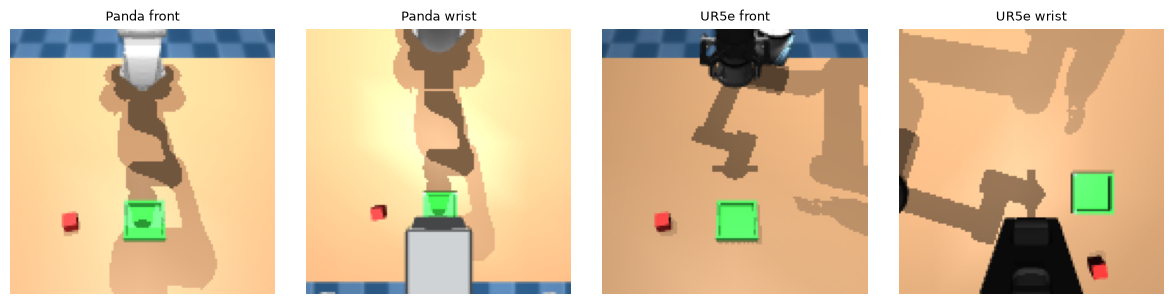

In [2]:
if not os.path.exists(os.path.join(UR, "meta.json")):
    t0 = time.time(); collect_parallel(UR, 80, seed=3, robot="ur5e", scene=SCENE); print(f"collected UR5e demos in {time.time() - t0:.0f}s")
env_ur = TableTop(scene=SCENE, robot="ur5e", cameras=("front", "wrist"), image_size=(128, 128), seed=0)
env_pa = TableTop(scene=SCENE, robot="panda", cameras=("front", "wrist"), image_size=(128, 128), seed=0)
o1, o2 = env_pa.reset(seed=4), env_ur.reset(seed=4)
show_images([o1["images"]["front"], o1["images"]["wrist"], o2["images"]["front"], o2["images"]["wrist"]], ["Panda front", "Panda wrist", "UR5e front", "UR5e wrist"], cols=4)

In [3]:
ds = TableTopDataset(UR, episodes=range(50), horizon=H)
variants = {}
for name, init in [("zero-shot Panda policy", "panda"), ("UR5e from scratch (50 demos)", None), ("Panda policy fine-tuned on 50 UR5e demos", "panda_ft")]:
    net = FlowPolicy(horizon=H)
    if init in ("panda", "panda_ft"):
        net.load_state_dict(torch.load(PANDA_CKPT, map_location=device))
    net.to(device)
    if init != "panda":
        path = f"checkpoints/ur5e_{'ft' if init else 'scratch'}.pt"
        if os.path.exists(path):
            net.load_state_dict(torch.load(path, map_location=device))
        else:
            t0 = time.time(); train_policy(net, ds, epochs=40 if init is None else 15, lr=1e-4 if init is None else 3e-5, device=device)
            torch.save(net.state_dict(), path); print(f"{name}: trained in {time.time() - t0:.0f}s")
    variants[name] = net.eval()

UR5e from scratch (50 demos): trained in 41s


Panda policy fine-tuned on 50 UR5e demos: trained in 14s


zero-shot Panda policy                     UR5e success 0.00 CI [-0.00, 0.09] per task {'pick': 0.0, 'place': 0.0}


UR5e from scratch (50 demos)               UR5e success 0.50 CI [0.35, 0.65] per task {'pick': 0.47619047619047616, 'place': 0.5263157894736842}


Panda policy fine-tuned on 50 UR5e demos   UR5e success 0.88 CI [0.74, 0.95] per task {'pick': 0.8095238095238095, 'place': 0.9473684210526315}


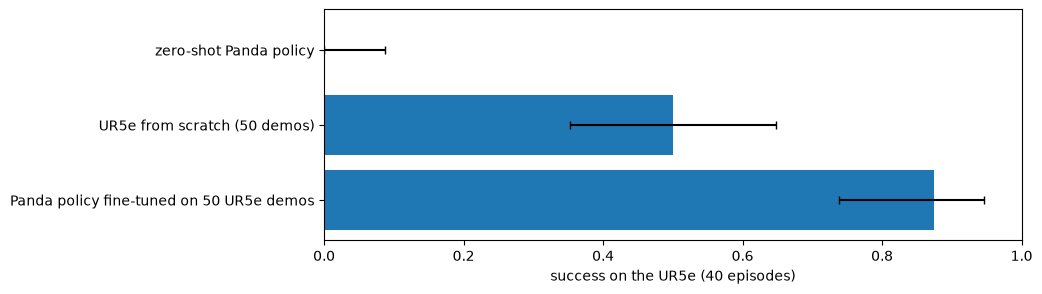

In [4]:
results = {}
for name, net in variants.items():
    pol_ds = ds if name != "zero-shot Panda policy" else TableTopDataset(scene_dataset(SCENE), episodes=range(450), horizon=H)
    r = evaluate(env_ur, ChunkPolicy(net, pol_ds, env_ur, device, execute=8, nfe=4), n_episodes=40, seed=80_000)
    results[name] = r
    print(f"{name:42s} UR5e success {r['success']:.2f} CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}] per task {r['per_task']}")
names = list(results); s = np.array([results[n]["success"] for n in names]); ci = np.array([results[n]["ci"] for n in names])
plt.figure(figsize=(9, 3)); plt.barh(names, s, xerr=[s - ci[:, 0], ci[:, 1] - s], capsize=3); plt.xlim(0, 1); plt.gca().invert_yaxis(); plt.xlabel("success on the UR5e (40 episodes)"); plt.show()
os.makedirs("results", exist_ok=True)
json.dump({n: dict(success=r["success"], ci=r["ci"]) for n, r in results.items()}, open("results/new_embodiment.json", "w"), indent=1)

### Watch it: a Panda policy driving a UR5e
Zero-shot transfer vs the same policy after fine-tuning on 50 UR5e demonstrations.

In [5]:
from vlacourse import showcase as sc
zs, ft = "zero-shot Panda policy", "Panda policy fine-tuned on 50 UR5e demos"
pa_ds = TableTopDataset(scene_dataset(SCENE), episodes=range(450), horizon=H)
sc.compare(env_ur, {"zero-shot (Panda policy)": ChunkPolicy(variants[zs], pa_ds, env_ur, device, execute=8, nfe=4),
                     "fine-tuned on 50 UR5e demos": ChunkPolicy(variants[ft], ds, env_ur, device, execute=8, nfe=4)},
           seed=sc.pick_seed(results[ft], results[zs], 80_000), title="132 UR5e zero-shot vs fine-tuned")

132 UR5e zero-shot vs fine-tuned: zero-shot (Panda policy): failed | fine-tuned on 50 UR5e demos: success


[False, True]